# View model outputs

Reads every JSON payload under `dho_data/llm_runs` and charts what the models returned: whether the call succeeded, what it cost, how many tokens it used, and the success and failure probabilities written in the forecast.

Run the cells from top to bottom. Add a new run by executing `capstone.ipynb`, then run this notebook again.

Sections 16 through 23 are the study checks: which forecasts exist, whether one success percent hides two questions, whether a rerun moves the number, ROI minus WACC, deal structure, conflicting deal terms, missing facts versus how tight the percent is, and language that describes an outcome that has already happened.


## 1. Load the payloads

In [1]:
from pathlib import Path
import json
import re

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "dho_data").exists():
    ROOT = Path("/Users/apizzini/Desktop/Capstone")
RUNS = ROOT / "dho_data" / "llm_runs"


def load_payloads(folder):
    """Read each provider JSON. Skip Jupyter checkpoint copies."""
    rows = []
    calls = []
    for path in sorted(folder.rglob("*.json")):
        if any("checkpoint" in part for part in path.parts):
            continue
        payload = json.loads(path.read_text())
        deal_id = payload.get("deal_id") or path.parent.parent.name
        stamp = path.parent.name
        profile = payload.get("profile") or ""
        forecast = payload.get("forecast") or ""
        rows.append({
            "deal_id": deal_id,
            "stamp": stamp,
            "provider": payload.get("provider"),
            "model": payload.get("model"),
            "ok": not payload.get("error") and bool(forecast),
            "error": (payload.get("error") or "").split("\n")[0][:180],
            "profile_chars": len(profile),
            "forecast_chars": len(forecast),
            "forecast": forecast,
        })
        for call in payload.get("calls") or []:
            calls.append({
                "deal_id": deal_id,
                "stamp": stamp,
                "provider": payload.get("provider"),
                "model": payload.get("model"),
                "prompt": call.get("prompt"),
                "input_tokens": call.get("input_tokens") or 0,
                "output_tokens": call.get("output_tokens") or 0,
                "usd": call.get("usd"),
            })
    return pd.DataFrame(rows), pd.DataFrame(calls)


runs, calls = load_payloads(RUNS)
print(f"{len(runs)} payload files, {int(runs['ok'].sum())} with a forecast")
runs[["deal_id", "stamp", "provider", "model", "ok", "profile_chars", "forecast_chars"]]


def deal_provider_bars(frame, value, title, ylabel, ylim=None):
    """One cluster per deal, one color per model, so the deal ids stay readable."""
    pivot = frame.pivot_table(index="deal_id", columns="provider", values=value, aggfunc="mean")
    fig, ax = plt.subplots(figsize=(11, 5))
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.legend(title="")
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
    fig.tight_layout()
    plt.show()
    return pivot


241 payload files, 184 with a forecast


## 2. Which calls succeeded

Each bar is one provider. A failed call is a payload that stored an error, or that never wrote a forecast.

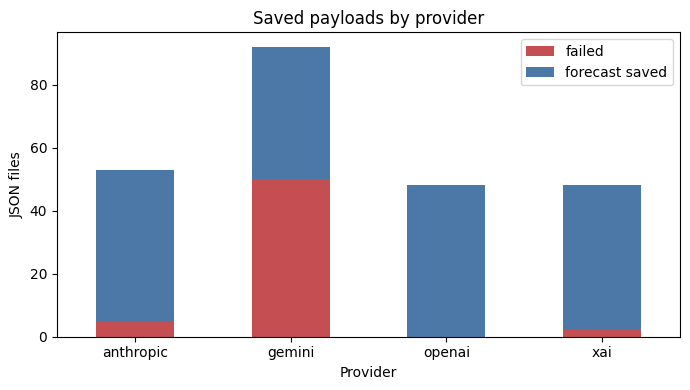

,deal_id,stamp,provider,model,error
1,BOW-AMFAM,20261027T162504Z,gemini,gemini-3.1-pro-preview,HTTP 503: {
4,BOW-AMFAM,20261028T103726Z,gemini,gemini-3.1-pro-preview,HTTP 403: {
15,BWMN-BERNHARD,20261027T154708Z,gemini,gemini-3.1-pro-preview,HTTP 503: {
18,BWMN-BERNHARD,20261027T154713Z,gemini,gemini-3.1-pro-preview,HTTP 503: {
19,BWMN-BERNHARD,20261027T154721Z,gemini,gemini-3.1-pro-preview,HTTP 503: {
21,BWMN-BERNHARD,20261027T161803Z,gemini,gemini-3.1-pro-preview,HTTP 503: {
24,BWMN-BERNHARD,20261028T103725Z,gemini,gemini-3.1-pro-preview,HTTP 403: {
35,CSR-IRT,20261027T155003Z,gemini,gemini-3.1-pro-preview,HTTP 503: {
38,CSR-IRT,20261027T155137Z,gemini,gemini-3.1-pro-preview,HTTP 503: {
40,CSR-IRT,20261027T162005Z,gemini,gemini-3.1-pro-preview,HTTP 503: {


In [2]:
status = runs.copy()
status["result"] = status["ok"].map({True: "forecast saved", False: "failed"})
counts = status.groupby(["provider", "result"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", stacked=True, ax=ax, color=["#c44e52", "#4c78a8"])
ax.set_title("Saved payloads by provider")
ax.set_xlabel("Provider")
ax.set_ylabel("JSON files")
ax.legend(title="")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()

failed = runs.loc[~runs["ok"], ["deal_id", "stamp", "provider", "model", "error"]]
failed


## 3. Cost of each prompt

The profile call sends the filing excerpt. The forecast call sends only the profile plus the success-or-failure question. Dollars use the token price stored in the payload.

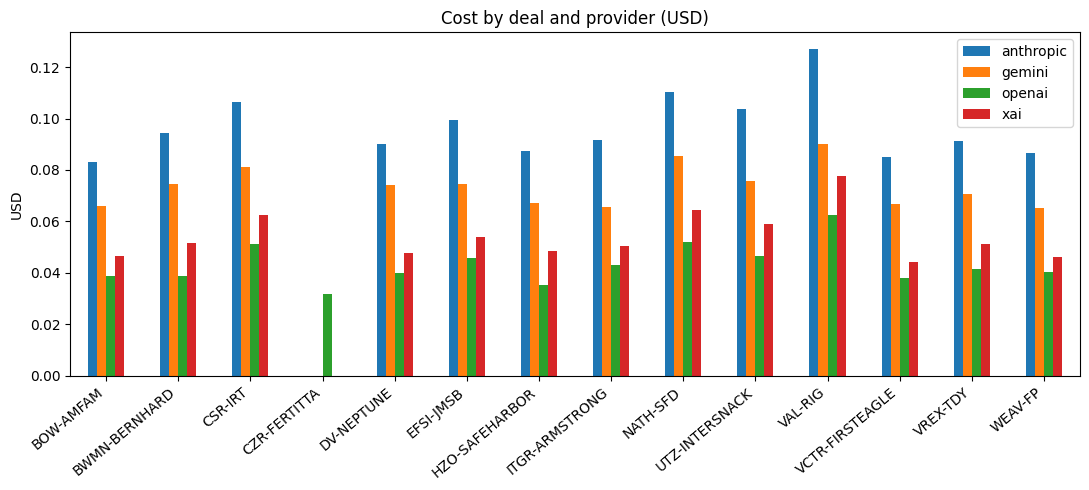

Total stored cost: $24.6252


In [3]:
priced = calls.dropna(subset=["usd"]).copy()
if priced.empty:
    print("No priced calls yet.")
else:
    deal_provider_bars(priced, "usd", "Cost by deal and provider (USD)", "USD")
    print(f"Total stored cost: ${priced['usd'].sum():,.4f}")
    priced.pivot_table(index="deal_id", columns=["provider", "prompt"], values="usd", aggfunc="sum").round(4)


## 4. Tokens in and tokens out

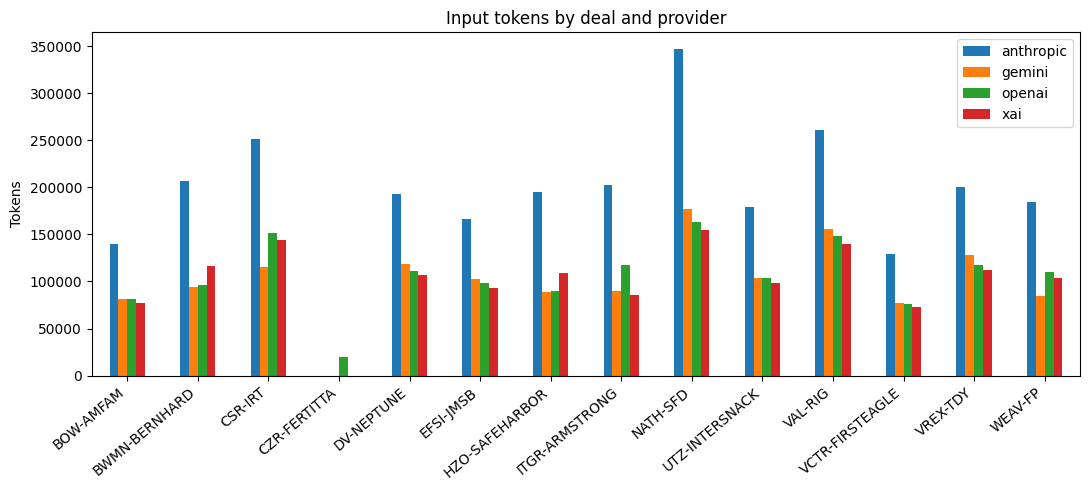

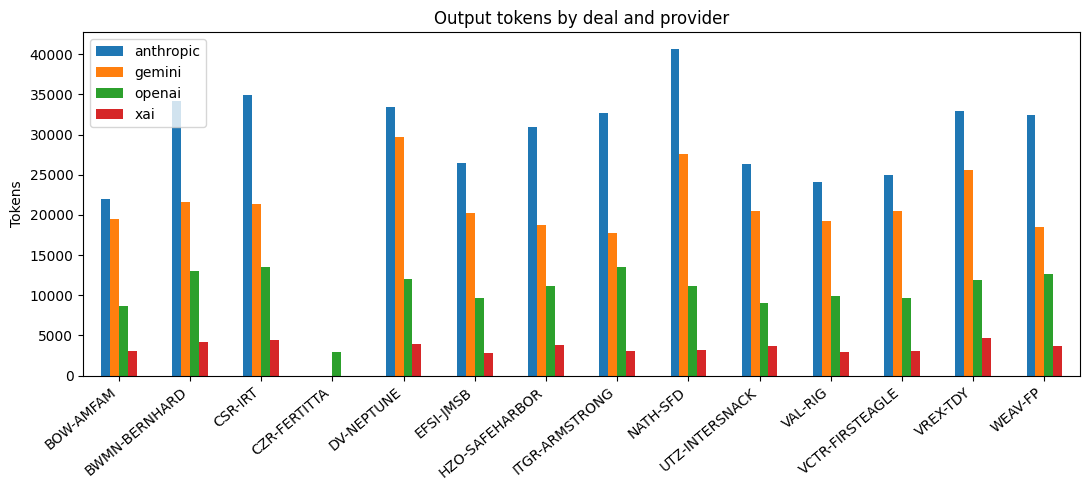

In [4]:
if calls.empty:
    print("No token counts yet.")
else:
    totals = calls.groupby(["deal_id", "provider"], as_index=False)[["input_tokens", "output_tokens"]].sum()
    deal_provider_bars(totals, "input_tokens", "Input tokens by deal and provider", "Tokens")
    deal_provider_bars(totals, "output_tokens", "Output tokens by deal and provider", "Tokens")
    totals


## 5. Success and failure probabilities

These numbers are read out of the forecast prose. They are not a separate field in the JSON. A range such as 80–85% is drawn at its midpoint. A forecast with no parseable percent is left off the chart.

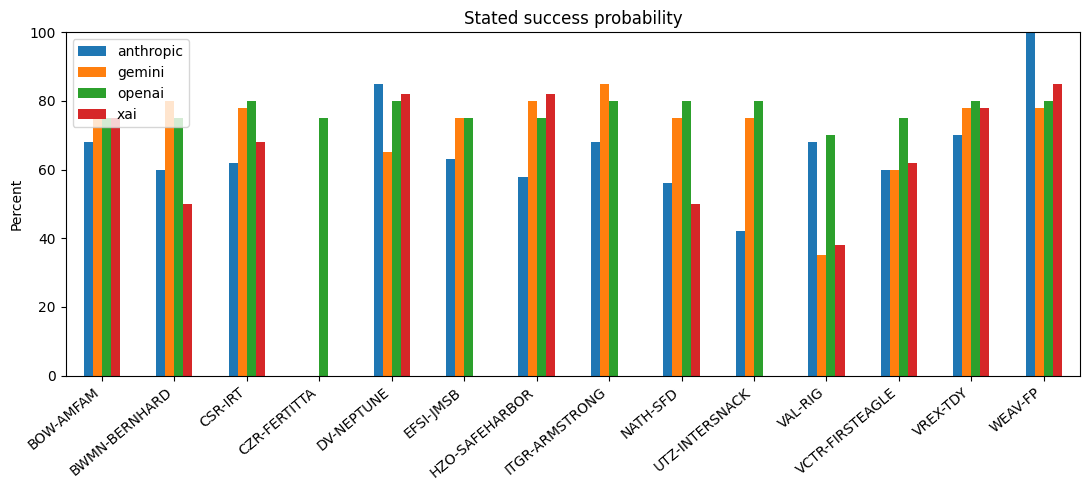

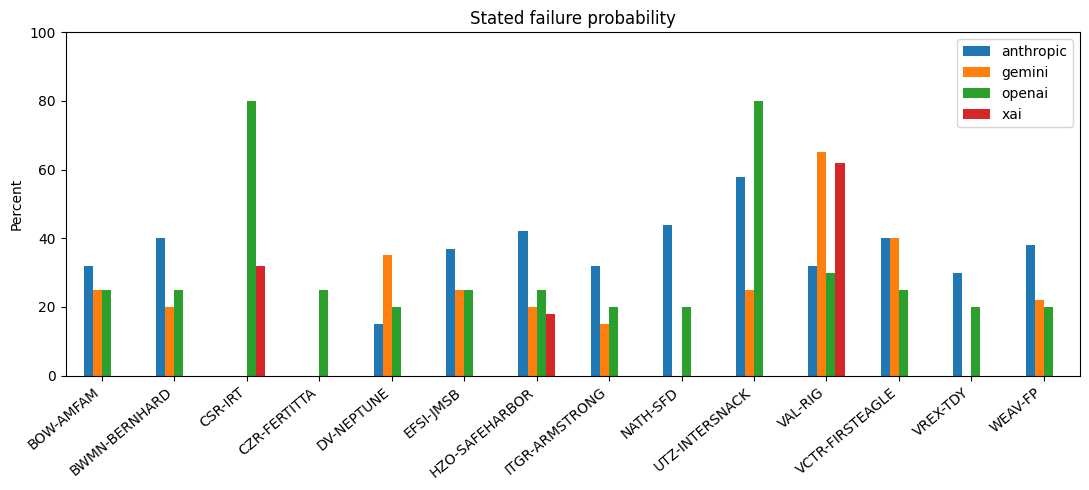

In [5]:
def midpoint(raw):
    """Turn '80-85' or '75' into a single percent."""
    parts = re.split(r"[–-]", raw)
    numbers = [float(part) for part in parts]
    return sum(numbers) / len(numbers)


def first_percent(text, labels):
    """Find the first percent that follows one of the labels."""
    pattern = "(?:" + "|".join(labels) + r").{0,60}?~?\**(\d{1,3}(?:\s*[–-]\s*\d{1,3})?)\s*%"
    match = re.search(pattern, text, flags=re.IGNORECASE | re.DOTALL)
    if not match:
        return None
    return midpoint(re.sub(r"\s+", "", match.group(1)))


def overall_pair(text):
    """Claude writes one row: Overall success, then failure."""
    match = re.search(
        r"Overall.{0,50}?~?\**(\d{1,3})\s*%.{0,40}?~?\**(\d{1,3})\s*%",
        text,
        flags=re.IGNORECASE | re.DOTALL,
    )
    if not match:
        return None
    return float(match.group(1)), float(match.group(2))


def line_percent(text, label):
    """Percent on the first line that contains the label, ignoring a parenthetical hurdle."""
    for line in text.splitlines():
        if not re.search(label, line, flags=re.IGNORECASE):
            continue
        cleaned = re.sub(r"\([^)]*\)", " ", line)
        match = re.search(
            r"[≈~*\s]*(\d{1,3}(?:\.\d+)?(?:\s*[–-]\s*\d{1,3}(?:\.\d+)?)?)\s*%",
            cleaned,
        )
        if not match:
            match = re.search(
                r"[≈~*\s]*(\d{1,3}(?:\.\d+)?(?:\s*[–-]\s*\d{1,3}(?:\.\d+)?)?)\s*%",
                line,
            )
        if match:
            return midpoint(re.sub(r"\s+", "", match.group(1)))
    return None


def read_probabilities(text):
    """Pull the success and failure percentages the model wrote."""
    pair = overall_pair(text)
    if pair:
        return {"p_success": pair[0], "p_failure": pair[1]}
    success = first_percent(text, ["probability of success", "success probability"])
    failure = first_percent(text, ["probability of failure", "failure probability"])
    if success is None:
        success = line_percent(text, r"\|\s*\**\s*Success\b")
    if success is None:
        success = line_percent(text, r"acceptable return|return hurdle")
    if failure is None:
        failure = line_percent(text, r"\|\s*\**\s*Failure\b")
    return {"p_success": success, "p_failure": failure}


scored = runs.loc[runs["ok"]].copy()
parsed = scored["forecast"].apply(read_probabilities).apply(pd.Series).reset_index(drop=True)
scored = pd.concat([scored.reset_index(drop=True), parsed], axis=1)
view = scored[["deal_id", "stamp", "provider", "model", "p_success", "p_failure"]]
view

plotable = (
    scored.dropna(subset=["p_success"])
    .sort_values("stamp")
    .groupby(["deal_id", "provider"], as_index=False)
    .tail(1)
)
if plotable.empty:
    print("No success probability could be read from the forecasts.")
else:
    deal_provider_bars(plotable, "p_success", "Stated success probability", "Percent", (0, 100))
    failure = plotable.dropna(subset=["p_failure"])
    if not failure.empty:
        deal_provider_bars(failure, "p_failure", "Stated failure probability", "Percent", (0, 100))


## 6. How long each answer was

Character counts of the profile and the forecast. A long profile is the filing summary. A forecast cut off near 4,096 tokens often means the model hit the output cap.

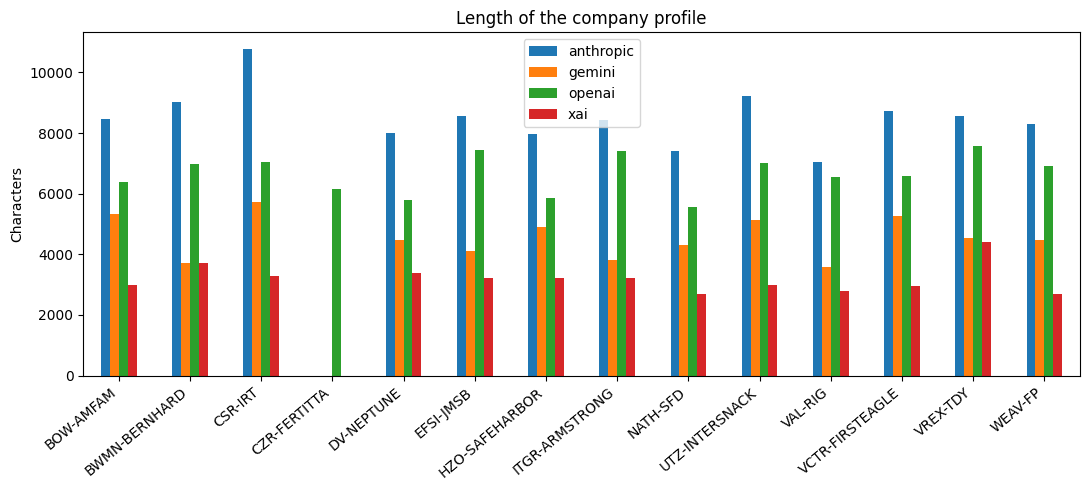

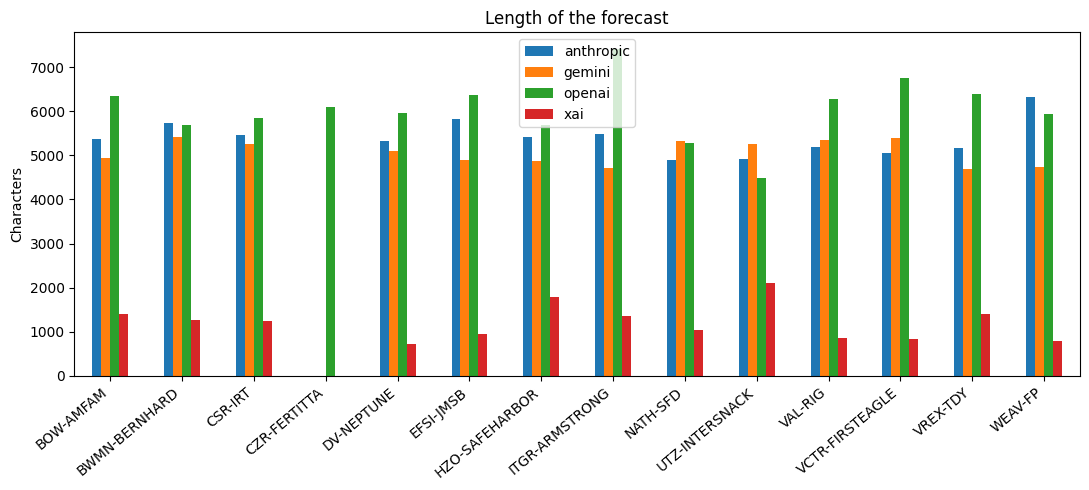

In [6]:
written = runs.loc[runs["profile_chars"] + runs["forecast_chars"] > 0].copy()
written = written.sort_values("stamp").groupby(["deal_id", "provider"], as_index=False).tail(1)
if written.empty:
    print("No written answers yet.")
else:
    deal_provider_bars(written, "profile_chars", "Length of the company profile", "Characters")
    deal_provider_bars(written, "forecast_chars", "Length of the forecast", "Characters")


## 7. Read one forecast

Change `DEAL_ID` and `PROVIDER` to open the latest saved text for that pair.

In [7]:
DEAL_ID = "ITGR-ARMSTRONG"
PROVIDER = "openai"

chosen = runs[(runs["deal_id"] == DEAL_ID) & (runs["provider"] == PROVIDER) & runs["ok"]]
if chosen.empty:
    print(f"No successful {PROVIDER} forecast for {DEAL_ID}.")
else:
    latest = chosen.sort_values("stamp").iloc[-1]
    print(latest["model"], latest["stamp"])
    print(latest["forecast"])


gpt-4.1 20261109T150448Z
Certainly! Let’s break down your request into the following steps:

1. **Assess the probability of success or failure of the Armstrong Parent, Inc. (KKR) acquisition of Integer Holdings Corporation (ITGR), based on the provided facts.**
2. **If success is more likely, estimate ROI, WACC, and ROA five years post-acquisition.**
3. **If failure is more likely, analyze causes and predict financial outcomes.**

---

## 1. Probability of Success vs. Failure

### **Key Success Factors**
- **Strong Sponsor:** KKR is a top-tier global private equity firm with deep experience in healthcare and leveraged buyouts.
- **All-Cash Offer:** $127/share, 51.8% premium, signals seriousness and strong financial backing.
- **No Financing Condition:** Equity and debt commitments are in place; ITGR is a third-party beneficiary of the equity commitment letter.
- **Board Approval:** Unanimous ITGR board approval and a fairness opinion from Goldman Sachs.
- **Clear Process:** Strategic r

In [8]:
DEAL_ID = "WEAV-FP"
PROVIDER = "openai"

chosen = runs[(runs["deal_id"] == DEAL_ID) & (runs["provider"] == PROVIDER) & runs["ok"]]
if chosen.empty:
    print(f"No successful {PROVIDER} forecast for {DEAL_ID}.")
else:
    latest = chosen.sort_values("stamp").iloc[-1]
    print(latest["model"], latest["stamp"])
    print(latest["forecast"])


gpt-4.1 20261109T150727Z
Given the information provided, we can perform a **qualitative and quantitative assessment** of the likely outcome of the Willow Parent, LLC (Francisco Partners) acquisition of Weave Communications, Inc. However, **key financial data is missing** (revenue, EBITDA, cash flow, debt, etc.), so all quantitative projections will be based on industry benchmarks and reasonable assumptions for a vertical SaaS healthcare company and a typical Francisco Partners deal.

---

## 1. Probability of Success vs. Failure

### **Qualitative Success Factors**
- **Sponsor Quality:** Francisco Partners is a top-tier global private equity firm with deep experience in technology and SaaS.
- **Deal Structure:** All-cash, with committed equity and potential debt, and a clear path to closing (subject to standard conditions).
- **Target Profile:** Weave is a vertical SaaS company in healthcare, a sector with strong secular growth, high switching costs, and sticky customer bases.
- **Boar

In [9]:
DEAL_ID = "WEAV-FP"
PROVIDER = "xai"

chosen = runs[(runs["deal_id"] == DEAL_ID) & (runs["provider"] == PROVIDER) & runs["ok"]]
if chosen.empty:
    print(f"No successful {PROVIDER} forecast for {DEAL_ID}.")
else:
    latest = chosen.sort_values("stamp").iloc[-1]
    print(latest["model"], latest["stamp"])
    print(latest["forecast"])

grok-3 20261109T150727Z
**Insufficient information for prediction.**

The provided company profile and situational analysis contain no financial metrics (revenue, EBITDA, market cap, debt/cash, shares outstanding), no valuation details (premium paid, implied enterprise value), no synergies estimates, and no post-deal operating or capital-structure projections. Without these inputs, any assignment of success/failure probability, ROI, WACC, ROA, or predictive financial outcomes would be speculative and unsupported by the filings.

Standard reverse-triangular merger mechanics, HSR/stockholder approval conditions, and termination-fee asymmetry are described, but these alone do not allow a reliable forward-looking assessment five years post-close. A data-driven forecast requires the missing quantitative elements.


In [10]:
DEAL_ID = "NATH-SFD"
PROVIDER = "xai"

chosen = runs[(runs["deal_id"] == DEAL_ID) & (runs["provider"] == PROVIDER) & runs["ok"]]
if chosen.empty:
    print(f"No successful {PROVIDER} forecast for {DEAL_ID}.")
else:
    latest = chosen.sort_values("stamp").iloc[-1]
    print(latest["model"], latest["stamp"])
    print(latest["forecast"])

grok-3 20261109T151026Z
**Prediction: Likely successful (65-70% probability).**

Francisco Partners has a strong track record investing in vertical SaaS and technology-enabled services. Weave’s AI-powered healthcare communications platform aligns directly with that focus, and the board’s unanimous approval plus the straightforward majority-vote condition reduce execution risk. The all-cash structure at a modest $7.40/share also limits post-deal leverage pressure compared with highly leveraged buyouts.

**Why not higher confidence?**  
Critical inputs are absent (purchase premium, expected synergies, termination fees, outside date, debt/EBITDA multiples, and any go-shop or financing conditions). Without those, the probability cannot be refined beyond the 65-70% range.

**Financial metrics 5 years post-close**  
No capital-structure, revenue, EBITDA, or synergy figures are provided in the materials. Therefore, specific 5-year ROI, WACC, or ROA projections cannot be calculated. Any numeri

In [11]:
DEAL_ID = "ITGR-ARMSTRONG"
PROVIDER = "anthropic"

chosen = runs[(runs["deal_id"] == DEAL_ID) & (runs["provider"] == PROVIDER) & runs["ok"]]
if chosen.empty:
    print(f"No successful {PROVIDER} forecast for {DEAL_ID}.")
else:
    latest = chosen.sort_values("stamp").iloc[-1]
    print(latest["model"], latest["stamp"])
    print(latest["forecast"])

claude-sonnet-5-5 20261109T150448Z

# Integer Holdings / KKR (Armstrong Parent): Outcome Prediction

## 1. Bottom line

| Outcome | Probability |
|---|---|
| **Success** (closes, then delivers a sponsor return of about 15% IRR or better) | **~68%** |
| **Failure** (does not close, or closes but underperforms) | **~32%** |

I split the estimate into two stages, since "success" means different things before and after closing.

| Stage | Probability | Main drivers |
|---|---|---|
| Deal closes by the May 2, 2027 outside date | ~92% | See the stage 1 table below. |
| Closes and meets the return threshold | ~74% | See section 3. |
| **Combined success** | **~68%** | 0.92 × 0.74 |

Success is the more likely outcome, so section 3 gives ROI, WACC and ROA at year 5.

**Important caveat:** The filings provided omit the share count, debt, revenue, EBITDA, financing terms and synergies. The financial figures below are not from the filings. They are my own illustrative assumptions, built from my g

## 8. Compare situational analyses

Each model writes its own profile. This section keeps only the situational analysis, then checks whether the models mention the same deal facts. A fact is counted when the words appear in that model's analysis. It is not a check that the number is correct.

In [12]:
def situational_text(profile):
    """Return the situational-analysis section, or the whole profile if the heading is missing."""
    match = re.search(
        r"(?:^|\n)\s*(?:#{1,3}\s*|\*\*)?2[\).]\s*Situational analysis\**\s*",
        profile,
        flags=re.IGNORECASE,
    )
    if not match:
        return profile.strip()
    return profile[match.end():].strip()


FACT_PATTERNS = {
    "premium": r"premium",
    "per-share price": r"\$\s?\d",
    "termination fee": r"termination fee",
    "outside date": r"outside date",
    "cash deal": r"\bcash\b",
    "stock deal": r"\bstock\b",
    "regulatory": r"regulat|antitrust|approval",
    "financing": r"financ",
    "synergies": r"synerg",
}


def fact_flags(text):
    """True when a fact's words appear in the analysis."""
    flags = {}
    for name, pattern in FACT_PATTERNS.items():
        flags[name] = bool(re.search(pattern, text, flags=re.IGNORECASE))
    return flags


# The profile text is not kept in `runs`. Read it back from the JSON.
profile_rows = []
for path in sorted(RUNS.rglob("*.json")):
    if any("checkpoint" in part for part in path.parts):
        continue
    payload = json.loads(path.read_text())
    profile = payload.get("profile") or ""
    if not profile:
        continue
    analysis = situational_text(profile)
    deal_id = payload.get("deal_id") or path.parent.parent.name
    profile_rows.append({
        "deal_id": deal_id,
        "stamp": path.parent.name,
        "provider": payload.get("provider"),
        "model": payload.get("model"),
        "situational_chars": len(analysis),
        "situational": analysis,
        **fact_flags(analysis),
    })

situations = pd.DataFrame(profile_rows)
# Keep the latest analysis when a provider was run more than once on the same deal.
situations = (
    situations.sort_values("stamp")
    .groupby(["deal_id", "provider"], as_index=False)
    .tail(1)
    .reset_index(drop=True)
)
print(f"{len(situations)} situational analyses across {situations['deal_id'].nunique()} deals")
situations.drop(columns=["situational"])


53 situational analyses across 14 deals


,deal_id,stamp,provider,model,situational_chars,premium,per-share price,termination fee,outside date,cash deal,stock deal,regulatory,financing,synergies
0,CZR-FERTITTA,20261019T184116Z,openai,gpt-4.1,3378,True,True,True,True,True,True,True,True,True
1,ITGR-ARMSTRONG,20261109T150448Z,openai,gpt-4.1,4788,True,True,True,True,True,True,True,True,True
2,ITGR-ARMSTRONG,20261109T150448Z,xai,grok-3,1801,True,True,True,True,True,True,True,True,True
3,ITGR-ARMSTRONG,20261109T150448Z,anthropic,claude-sonnet-5-5,5069,True,True,True,True,True,False,True,True,True
4,ITGR-ARMSTRONG,20261109T150448Z,gemini,gemini-3.1-pro-preview,2285,True,True,True,True,True,True,True,True,True
5,WEAV-FP,20261109T150727Z,xai,grok-3,1510,True,True,True,True,True,True,True,False,True
6,WEAV-FP,20261109T150727Z,gemini,gemini-3.1-pro-preview,2740,True,True,True,True,True,False,True,False,True
7,WEAV-FP,20261109T150727Z,anthropic,claude-sonnet-5-5,5044,True,True,True,True,True,False,True,True,True
8,WEAV-FP,20261109T150727Z,openai,gpt-4.1,4557,True,True,True,True,True,True,True,True,True
9,NATH-SFD,20261109T151026Z,xai,grok-3,1440,True,True,True,True,True,True,True,False,True


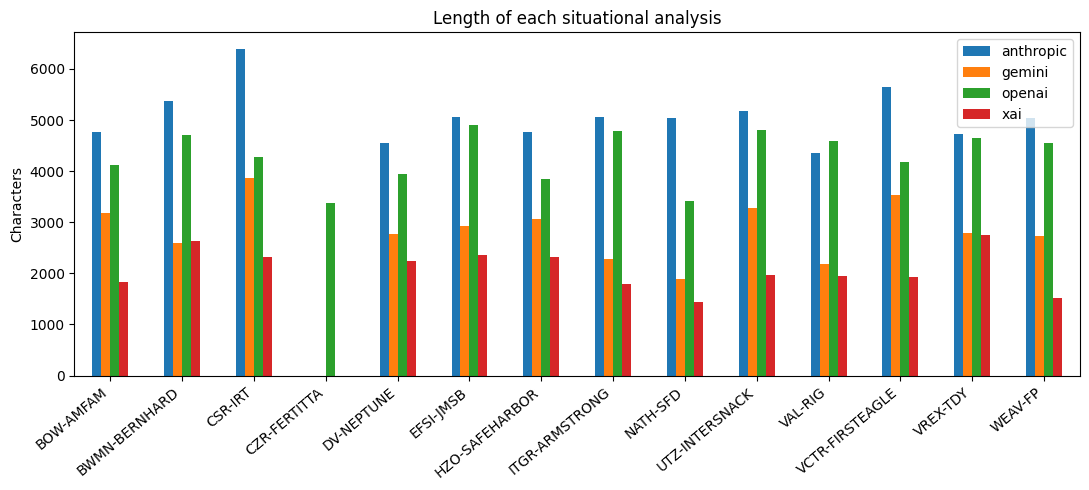

provider,anthropic,gemini,openai,xai
deal_id,,,,
BOW-AMFAM,4773.0,3174.0,4111.0,1835.0
BWMN-BERNHARD,5374.0,2590.0,4704.0,2640.0
CSR-IRT,6396.0,3865.0,4277.0,2322.0
CZR-FERTITTA,NaN,NaN,3378.0,NaN
DV-NEPTUNE,4558.0,2775.0,3941.0,2251.0
EFSI-JMSB,5063.0,2923.0,4906.0,2369.0
HZO-SAFEHARBOR,4758.0,3062.0,3840.0,2320.0
ITGR-ARMSTRONG,5069.0,2285.0,4788.0,1801.0
NATH-SFD,5037.0,1882.0,3411.0,1440.0


In [13]:
# Length of each model's situational analysis. One cluster per deal.
deal_provider_bars(situations, "situational_chars", "Length of each situational analysis", "Characters")


WEAV-FP — fact mentioned in the situational analysis
           premium  per-share price  termination fee  outside date  cash deal  stock deal  regulatory  financing  synergies
provider                                                                                                                   
xai           True             True             True          True       True        True        True      False       True
gemini        True             True             True          True       True       False        True      False       True
anthropic     True             True             True          True       True       False        True       True       True
openai        True             True             True          True       True        True        True       True       True
Mentioned by every model: premium, per-share price, termination fee, outside date, cash deal, regulatory, synergies
Mentioned by only some models: stock deal, financing
Mentioned by no model: none


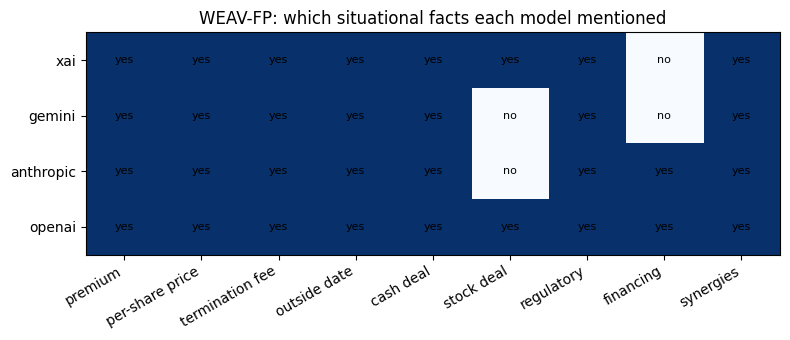

In [14]:
COMPARE_DEAL = "WEAV-FP"

deal_rows = situations[situations["deal_id"] == COMPARE_DEAL].copy()
if deal_rows.empty:
    print(f"No situational analysis saved for {COMPARE_DEAL}.")
else:
    fact_cols = list(FACT_PATTERNS)
    coverage = deal_rows.set_index("provider")[fact_cols]
    print(COMPARE_DEAL, "— fact mentioned in the situational analysis")
    print(coverage.to_string())

    shared = [col for col in fact_cols if coverage[col].all()]
    split = [col for col in fact_cols if coverage[col].any() and not coverage[col].all()]
    missing = [col for col in fact_cols if not coverage[col].any()]
    print("Mentioned by every model:", ", ".join(shared) or "none")
    print("Mentioned by only some models:", ", ".join(split) or "none")
    print("Mentioned by no model:", ", ".join(missing) or "none")

    fig, ax = plt.subplots(figsize=(8, 3.5))
    plot_data = coverage.astype(int)
    image = ax.imshow(plot_data.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(fact_cols)))
    ax.set_xticklabels(fact_cols, rotation=30, ha="right")
    ax.set_yticks(range(len(plot_data.index)))
    ax.set_yticklabels(plot_data.index)
    ax.set_title(f"{COMPARE_DEAL}: which situational facts each model mentioned")
    for row_i, provider in enumerate(plot_data.index):
        for col_i, fact in enumerate(fact_cols):
            ax.text(col_i, row_i, "yes" if plot_data.iloc[row_i, col_i] else "no", ha="center", va="center", fontsize=8)
    fig.tight_layout()
    plt.show()


DV-NEPTUNE — fact mentioned in the situational analysis
           premium  per-share price  termination fee  outside date  cash deal  stock deal  regulatory  financing  synergies
provider                                                                                                                   
anthropic     True             True             True          True       True       False        True       True       True
gemini        True             True             True          True       True        True        True       True       True
openai        True             True             True          True       True        True        True       True       True
xai           True             True             True          True       True        True        True       True       True
Mentioned by every model: premium, per-share price, termination fee, outside date, cash deal, regulatory, financing, synergies
Mentioned by only some models: stock deal
Mentioned by no model: none


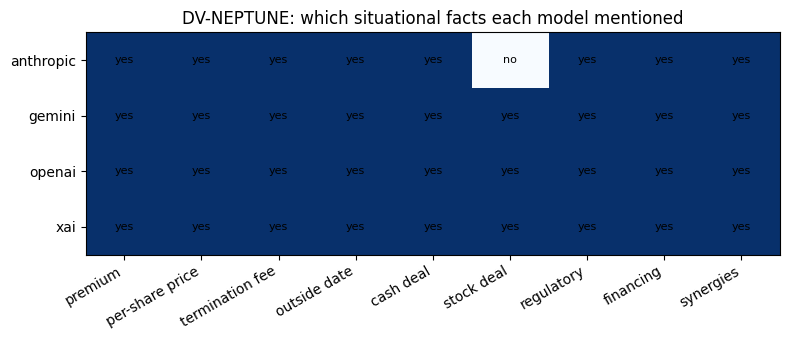

In [15]:
COMPARE_DEAL = "DV-NEPTUNE"

deal_rows = situations[situations["deal_id"] == COMPARE_DEAL].copy()
if deal_rows.empty:
    print(f"No situational analysis saved for {COMPARE_DEAL}.")
else:
    fact_cols = list(FACT_PATTERNS)
    coverage = deal_rows.set_index("provider")[fact_cols]
    print(COMPARE_DEAL, "— fact mentioned in the situational analysis")
    print(coverage.to_string())

    shared = [col for col in fact_cols if coverage[col].all()]
    split = [col for col in fact_cols if coverage[col].any() and not coverage[col].all()]
    missing = [col for col in fact_cols if not coverage[col].any()]
    print("Mentioned by every model:", ", ".join(shared) or "none")
    print("Mentioned by only some models:", ", ".join(split) or "none")
    print("Mentioned by no model:", ", ".join(missing) or "none")

    fig, ax = plt.subplots(figsize=(8, 3.5))
    plot_data = coverage.astype(int)
    image = ax.imshow(plot_data.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(fact_cols)))
    ax.set_xticklabels(fact_cols, rotation=30, ha="right")
    ax.set_yticks(range(len(plot_data.index)))
    ax.set_yticklabels(plot_data.index)
    ax.set_title(f"{COMPARE_DEAL}: which situational facts each model mentioned")
    for row_i, provider in enumerate(plot_data.index):
        for col_i, fact in enumerate(fact_cols):
            ax.text(col_i, row_i, "yes" if plot_data.iloc[row_i, col_i] else "no", ha="center", va="center", fontsize=8)
    fig.tight_layout()
    plt.show()

NATH-SFD — fact mentioned in the situational analysis
           premium  per-share price  termination fee  outside date  cash deal  stock deal  regulatory  financing  synergies
provider                                                                                                                   
xai           True             True             True          True       True        True        True      False       True
openai        True             True             True          True       True        True        True      False       True
gemini        True             True             True          True       True        True        True      False       True
anthropic     True             True             True          True       True        True        True       True       True
Mentioned by every model: premium, per-share price, termination fee, outside date, cash deal, stock deal, regulatory, synergies
Mentioned by only some models: financing
Mentioned by no model: none


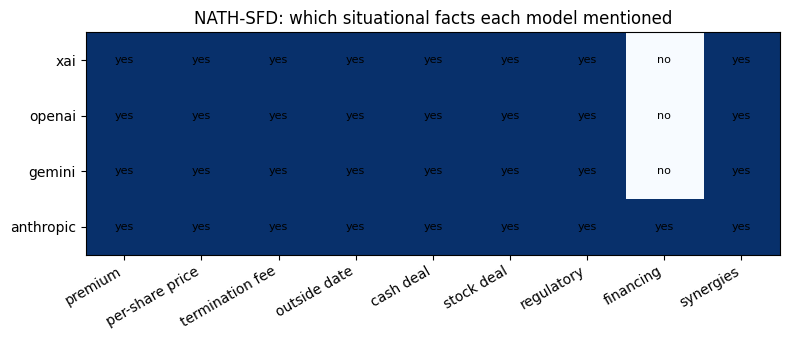

In [16]:
COMPARE_DEAL = "NATH-SFD"

deal_rows = situations[situations["deal_id"] == COMPARE_DEAL].copy()
if deal_rows.empty:
    print(f"No situational analysis saved for {COMPARE_DEAL}.")
else:
    fact_cols = list(FACT_PATTERNS)
    coverage = deal_rows.set_index("provider")[fact_cols]
    print(COMPARE_DEAL, "— fact mentioned in the situational analysis")
    print(coverage.to_string())

    shared = [col for col in fact_cols if coverage[col].all()]
    split = [col for col in fact_cols if coverage[col].any() and not coverage[col].all()]
    missing = [col for col in fact_cols if not coverage[col].any()]
    print("Mentioned by every model:", ", ".join(shared) or "none")
    print("Mentioned by only some models:", ", ".join(split) or "none")
    print("Mentioned by no model:", ", ".join(missing) or "none")

    fig, ax = plt.subplots(figsize=(8, 3.5))
    plot_data = coverage.astype(int)
    image = ax.imshow(plot_data.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(fact_cols)))
    ax.set_xticklabels(fact_cols, rotation=30, ha="right")
    ax.set_yticks(range(len(plot_data.index)))
    ax.set_yticklabels(plot_data.index)
    ax.set_title(f"{COMPARE_DEAL}: which situational facts each model mentioned")
    for row_i, provider in enumerate(plot_data.index):
        for col_i, fact in enumerate(fact_cols):
            ax.text(col_i, row_i, "yes" if plot_data.iloc[row_i, col_i] else "no", ha="center", va="center", fontsize=8)
    fig.tight_layout()
    plt.show()

In [17]:
# Full situational analyses for the deal above, one model after another.
if deal_rows.empty:
    print("Nothing to print.")
else:
    for _, row in deal_rows.sort_values("provider").iterrows():
        print("=" * 72)
        print(row["provider"], row["model"], row["stamp"])
        print("=" * 72)
        print(row["situational"])
        print()


anthropic claude-sonnet-5-5 20261109T151026Z
- **Structure:** Merger Sub merges into Weave, which survives as a wholly owned subsidiary of Parent. The Merger Agreement is dated August 18, 2026 (DEFM14A).
- **Consideration:** $7.40 in cash per share, less any withholding taxes (DEFM14A).
- **Premium:** Missing from the filings provided.
- **Aggregate equity or enterprise value:** Missing from the filings provided.
- **Synergies:** Missing. The sponsor structure suggests none are quantified, but the filing does not say.
- **Board and advisor:**
  - The board unanimously approved the deal and recommended adoption (DEFM14A).
  - Jefferies LLC gave a fairness opinion (Annex C, DEFM14A).
- **Stockholder vote:**
  - Adoption requires a majority of outstanding shares entitled to vote (DEFM14A).
  - The special meeting is October 22, 2026, at 10:00 a.m. ET, virtual.
  - The record date is September 14, 2026 (DEFM14A).
  - Support agreements exist, but the share counts they cover are missing.
- 

## 9. Where the models disagree

One bar per provider on each deal. The gap is the highest success percent minus the lowest, and it is left blank when only one model has a readable number. A range in the forecast is stored as its midpoint. Only the latest successful forecast for each provider is kept.


Success percent, and the spread between models
                 anthropic  gemini  openai   xai  gap_points
deal_id                                                     
BOW-AMFAM              NaN    75.0    75.0  75.0         0.0
BWMN-BERNHARD         60.0    80.0    75.0  50.0        30.0
CSR-IRT               62.0    78.0    80.0   NaN        18.0
CZR-FERTITTA           NaN     NaN    75.0   NaN         NaN
DV-NEPTUNE             NaN    65.0    80.0   NaN        15.0
EFSI-JMSB             63.0    75.0    75.0   NaN        12.0
HZO-SAFEHARBOR         NaN    80.0    75.0  82.0         7.0
ITGR-ARMSTRONG        68.0     NaN    80.0   NaN        12.0
NATH-SFD               NaN    75.0    80.0   NaN         5.0
UTZ-INTERSNACK         NaN    75.0    80.0   NaN         5.0
VAL-RIG               68.0    35.0    70.0   NaN        35.0
VCTR-FIRSTEAGLE       60.0    60.0    75.0   NaN        15.0
VREX-TDY              70.0    78.0    80.0  78.0        10.0
WEAV-FP              100.0    78.0    

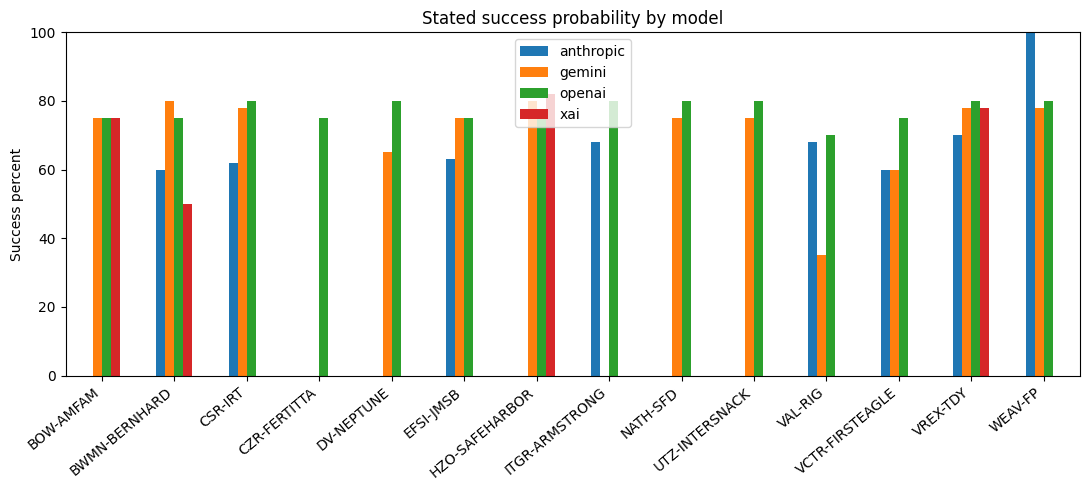

In [18]:
latest_scores = (
    scored.sort_values("stamp")
    .groupby(["deal_id", "provider"], as_index=False)
    .tail(1)
)
spread = latest_scores.pivot(index="deal_id", columns="provider", values="p_success")
n_models = spread.notna().sum(axis=1)
gap = (spread.max(axis=1) - spread.min(axis=1)).where(n_models >= 2).rename("gap_points")
print("Success percent, and the spread between models")
print(spread.round(1).join(gap.round(1)).to_string())

fig, ax = plt.subplots(figsize=(11, 5))
spread.plot(kind="bar", ax=ax)
ax.set_ylim(0, 100)
ax.set_ylabel("Success percent")
ax.set_xlabel("")
ax.set_title("Stated success probability by model")
ax.legend(title="")
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout()
plt.show()


## 10. ROI, WACC, and ROA

Each bar is the success-case percent written next to that label. A range is drawn at its midpoint. When a model gives both a cumulative return and an annualized return, the chart uses the annualized one. A blank means the model did not state that figure. These are reads from the forecast, not a check against the filings.


        deal_id  provider  roi  wacc  roa
   CZR-FERTITTA    openai 11.5   8.0  7.5
 ITGR-ARMSTRONG    openai 16.5  10.0 10.0
 ITGR-ARMSTRONG       xai  NaN   NaN  NaN
 ITGR-ARMSTRONG anthropic  7.0   9.0  2.0
 ITGR-ARMSTRONG    gemini 20.0   6.0  4.0
        WEAV-FP       xai  NaN   NaN  NaN
        WEAV-FP    gemini  NaN  11.5  8.0
        WEAV-FP anthropic 13.0  11.5  7.0
        WEAV-FP    openai  9.0  11.0 20.0
       NATH-SFD       xai  NaN   NaN  NaN
       NATH-SFD    openai 13.5   8.0 11.0
       NATH-SFD    gemini 12.0  12.0 12.0
       NATH-SFD anthropic  6.0   3.5  6.0
       VREX-TDY       xai  NaN   NaN  NaN
       VREX-TDY anthropic 15.0   8.5  4.7
       VREX-TDY    openai 27.5   8.8  8.5
       VREX-TDY    gemini 15.0   8.7  8.2
     DV-NEPTUNE anthropic 30.0   6.8  4.5
     DV-NEPTUNE    gemini 20.0   8.5  6.0
     DV-NEPTUNE    openai  8.7   8.7 10.0
     DV-NEPTUNE       xai  NaN   NaN  NaN
  BWMN-BERNHARD       xai  NaN   NaN  NaN
  BWMN-BERNHARD    gemini 15.0  18

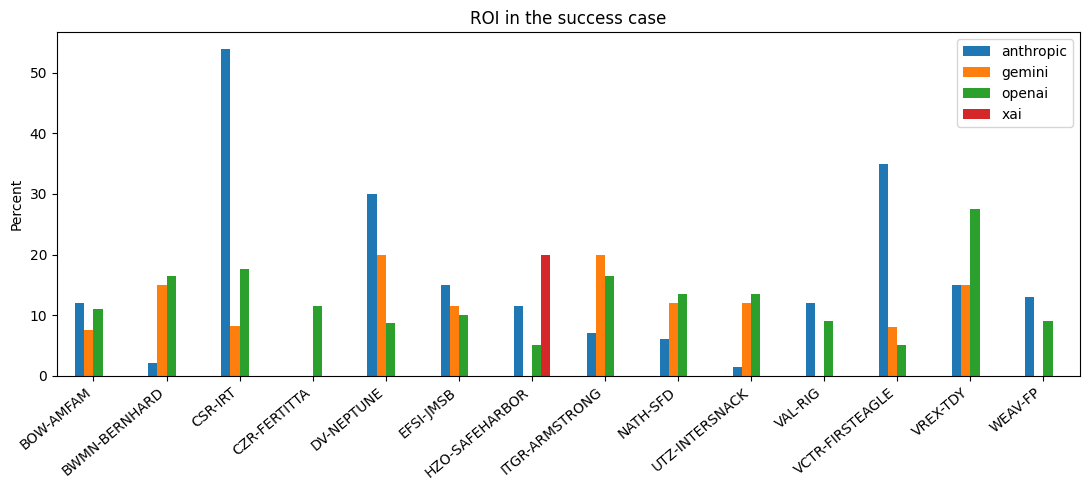

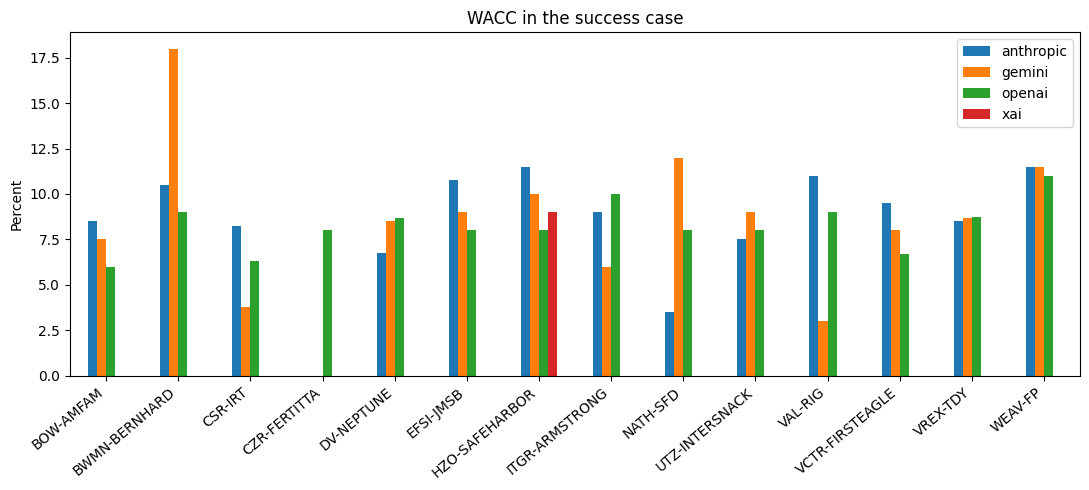

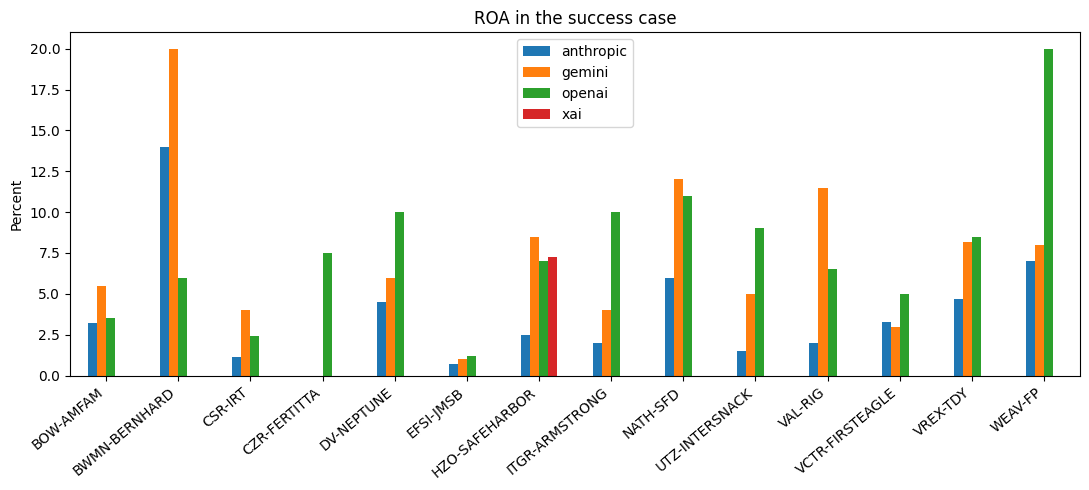

In [19]:
def _midpoint(raw):
    parts = re.split(r"[–\-−]", raw)
    return sum(float(part) for part in parts) / len(parts)


_PCT = r"(\d{1,3}(?:\.\d+)?(?:\s*[–\-−]\s*\d{1,3}(?:\.\d+)?)?)\\?\s*%"
_IRR = re.compile(
    r"(\d{1,2}(?:\.\d+)?(?:\s*[–\-−]\s*\d{1,2}(?:\.\d+)?)?)\s*%\s*(?:IRR|internal rate of return)"
    r"|(?:IRR|internal rate of return)[^%\d]{0,16}[≈~]?\s*(\d{1,2}(?:\.\d+)?(?:\s*[–\-−]\s*\d{1,2}(?:\.\d+)?)?)\s*%",
    re.IGNORECASE,
)


def _percent_values(window, limit):
    values = []
    for found in re.finditer(_PCT, window):
        around = window[max(0, found.start() - 12):found.end() + 10]
        if re.search(r"tax", around, flags=re.IGNORECASE):
            continue
        value = _midpoint(found.group(1).replace(" ", ""))
        if 0 < value <= limit:
            values.append(value)
    return values


def _irr_value(window):
    found = []
    for line in window.splitlines():
        if re.search(r"\bbear\b|downside", line, flags=re.IGNORECASE):
            continue
        match = _IRR.search(line)
        if not match:
            continue
        if re.search(r"above|at least|hurdle|≥", line[:match.start()], flags=re.IGNORECASE):
            continue
        raw = (match.group(1) or match.group(2) or "").replace(" ", "")
        if not raw:
            continue
        value = _midpoint(raw)
        if value <= 60:
            found.append(value)
    return found[-1] if found else None


def _forecast_lines(text):
    """Drop the failure write-up, then keep a summary table that follows it."""
    mode = "keep"
    lines = []
    for line in text.splitlines():
        if re.match(r"\s*#{1,3}\s*.*failure is more likely", line, flags=re.IGNORECASE):
            mode = "skip"
            continue
        if mode == "skip" and re.match(r"\s*#{1,3}\s+", line):
            mode = "keep"
        if mode == "keep":
            lines.append(line)
    return lines


def metric_percent(text, label, limit):
    """Last success-case percent written for ROI, WACC, or ROA."""
    lines = _forecast_lines(text)
    if label == "ROI":
        for line in lines:
            if re.search(r"\bbase\b", line, flags=re.IGNORECASE) and "|" in line:
                values = _percent_values(line, limit)
                if values:
                    return values[-1]
    hits = []
    for index, line in enumerate(lines):
        if re.search(r"\bbear\b|downside", line, flags=re.IGNORECASE):
            continue
        if not re.search(rf"\b{label}\b", line, flags=re.IGNORECASE):
            continue
        if re.search(r"cannot be derived|would be fabricated|speculative and unsupported", line, flags=re.IGNORECASE):
            continue
        cells = [cell.strip(" *") for cell in line.split("|")]
        cells = [cell for cell in cells if cell]
        others = [name for name in ("ROI", "WACC", "ROA") if name != label and re.search(rf"\b{name}\b", line, flags=re.IGNORECASE)]
        if cells and len(cells) >= 2 and not others and re.search(rf"\b{label}\b", cells[0], flags=re.IGNORECASE):
            blob = cells[1]
            annual = re.search(r"(\d{1,2}(?:\.\d+)?(?:\s*[–\-−]\s*\d{1,2}(?:\.\d+)?)?)\\?\s*%\s*annual", blob, flags=re.IGNORECASE)
            if label == "ROI" and annual:
                hits.append(_midpoint(annual.group(1).replace(" ", "")))
                continue
            if label == "ROI":
                irr = _irr_value(blob)
                if irr:
                    hits.append(irr)
                    continue
            values = _percent_values(blob, limit)
            if values:
                hits.append(values[0])
            continue
        located = re.search(rf"\b{label}\b", line, flags=re.IGNORECASE)
        span = line[located.end():located.end() + 180]
        if "%" not in span:
            span = "\n".join(lines[index:index + 5])
            start = span.lower().find(label.lower())
            span = span[start:start + 220]
        if label == "ROI":
            irr = _irr_value(span)
            if irr:
                hits.append(irr)
                continue
        values = _percent_values(span, limit)
        if not values:
            continue
        hits.append(values[-1] if "=" in span else values[0])
    return hits[-1] if hits else None


financials = latest_scores[["deal_id", "provider", "model", "forecast"]].copy()
financials["roi"] = financials["forecast"].apply(lambda text: metric_percent(text, "ROI", 60))
financials["wacc"] = financials["forecast"].apply(lambda text: metric_percent(text, "WACC", 20))
financials["roa"] = financials["forecast"].apply(lambda text: metric_percent(text, "ROA", 25))
print(financials.drop(columns=["forecast", "model"]).round(1).to_string(index=False))

for metric in ("roi", "wacc", "roa"):
    pivot = financials.pivot(index="deal_id", columns="provider", values=metric)
    if pivot.notna().sum().sum() == 0:
        print(f"No {metric.upper()} figures found.")
        continue
    fig, ax = plt.subplots(figsize=(11, 5))
    pivot.plot(kind="bar", ax=ax)
    ax.set_ylabel("Percent")
    ax.set_xlabel("")
    ax.set_title(metric.upper() + " in the success case")
    ax.legend(title="")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
    fig.tight_layout()
    plt.show()


## 11. Close versus value

Some models give one success percent. Others split the chance the deal closes from the chance it creates value after close. A blank cell means that model did not separate the two.

        deal_id  provider  p_close  p_value
   CZR-FERTITTA    openai      NaN      NaN
 ITGR-ARMSTRONG    openai      NaN      NaN
 ITGR-ARMSTRONG       xai     82.5      NaN
 ITGR-ARMSTRONG anthropic     92.0      NaN
 ITGR-ARMSTRONG    gemini      NaN      NaN
        WEAV-FP       xai      NaN      NaN
        WEAV-FP    gemini      NaN      NaN
        WEAV-FP anthropic     62.0     62.0
        WEAV-FP    openai      NaN      NaN
       NATH-SFD       xai      NaN      NaN
       NATH-SFD    openai      NaN      NaN
       NATH-SFD    gemini      NaN      NaN
       NATH-SFD anthropic      5.0      NaN
       VREX-TDY       xai      NaN      NaN
       VREX-TDY anthropic     88.0      NaN
       VREX-TDY    openai      NaN      NaN
       VREX-TDY    gemini      NaN      NaN
     DV-NEPTUNE anthropic     80.0      NaN
     DV-NEPTUNE    gemini      NaN      NaN
     DV-NEPTUNE    openai      NaN      NaN
     DV-NEPTUNE       xai      NaN      NaN
  BWMN-BERNHARD       xai      N

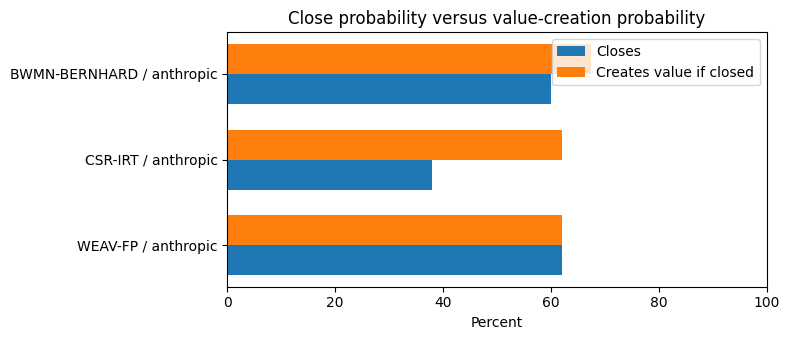

In [20]:
def close_and_value(text):
    """Chance the deal closes, and chance it creates value, when the model splits them."""
    close = line_percent(text, r"deal closes|probability the deal closes|probability it closes|deal likely closes")
    value = line_percent(text, r"creates value|acceptable return|return hurdle")
    return pd.Series({"p_close": close, "p_value": value})


split_view = latest_scores[["deal_id", "provider"]].copy()
split_view = pd.concat(
    [split_view.reset_index(drop=True), latest_scores["forecast"].apply(close_and_value).reset_index(drop=True)],
    axis=1,
)
print(split_view.round(1).to_string(index=False))
both = split_view.dropna(subset=["p_close", "p_value"])
if both.empty:
    print("No forecast separated close from value creation.")
else:
    both = both.sort_values(["deal_id", "provider"])
    labels = both["deal_id"] + " / " + both["provider"]
    y = list(range(len(both)))
    height = 0.35
    fig, ax = plt.subplots(figsize=(8, max(3.5, 0.48 * len(both))))
    ax.barh([i + height / 2 for i in y], both["p_close"], height=height, label="Closes")
    ax.barh([i - height / 2 for i in y], both["p_value"], height=height, label="Creates value if closed")
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percent")
    ax.set_title("Close probability versus value-creation probability")
    ax.legend()
    ax.invert_yaxis()
    fig.tight_layout()
    plt.show()


## 12. Risks named in the forecast

A yes means the words appear in the forecast. The lists under the chart are risks that only some models on that deal named.

BOW-AMFAM: named by only some models — vote, topping bid
BWMN-BERNHARD: named by only some models — vote, integration, topping bid
CSR-IRT: named by only some models — regulatory, integration, topping bid
DV-NEPTUNE: named by only some models — regulatory, integration, topping bid
EFSI-JMSB: named by only some models — vote, regulatory, leverage, topping bid
HZO-SAFEHARBOR: named by only some models — vote, topping bid
ITGR-ARMSTRONG: named by only some models — regulatory, integration, topping bid
NATH-SFD: named by only some models — regulatory, integration
UTZ-INTERSNACK: named by only some models — vote, topping bid
VAL-RIG: named by only some models — vote, regulatory
VCTR-FIRSTEAGLE: named by only some models — regulatory, leverage
VREX-TDY: named by only some models — vote, leverage, topping bid
WEAV-FP: named by only some models — vote, regulatory, integration, topping bid


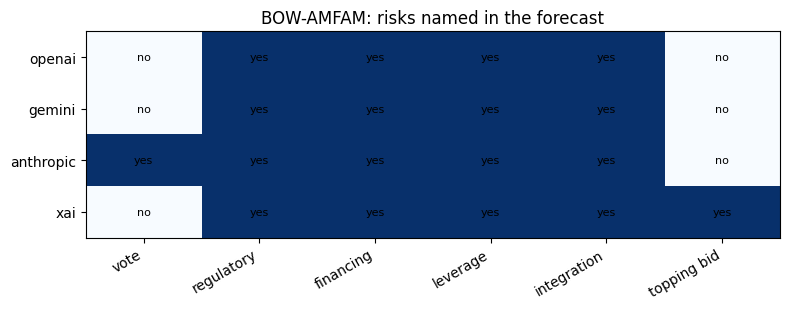

In [21]:
RISK_PATTERNS = {
    "vote": r"shareholder vote|stockholder vote|vote threshold",
    "regulatory": r"regulat|antitrust",
    "financing": r"financ",
    "leverage": r"leverag|debt",
    "integration": r"integrat",
    "topping bid": r"topping|higher bid|competing bid|superior offer",
}

def risk_flags(text):
    return {name: bool(re.search(pattern, text, flags=re.IGNORECASE)) for name, pattern in RISK_PATTERNS.items()}


risk_rows = latest_scores[["deal_id", "provider", "forecast"]].copy()
risk_rows = pd.concat(
    [risk_rows.reset_index(drop=True), risk_rows["forecast"].apply(risk_flags).apply(pd.Series).reset_index(drop=True)],
    axis=1,
)
for deal_id, group in risk_rows.groupby("deal_id"):
    grid = group.set_index("provider")[list(RISK_PATTERNS)]
    if len(grid) < 2:
        continue
    split = [col for col in grid.columns if grid[col].any() and not grid[col].all()]
    print(f"{deal_id}: named by only some models — {', '.join(split) or 'none'}")

# Heatmap for the deal with the most finished forecasts.
richest = risk_rows.groupby("deal_id")["provider"].nunique().idxmax()
grid = risk_rows[risk_rows["deal_id"] == richest].set_index("provider")[list(RISK_PATTERNS)].astype(int)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.imshow(grid.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(grid.columns)))
ax.set_xticklabels(grid.columns, rotation=30, ha="right")
ax.set_yticks(range(len(grid.index)))
ax.set_yticklabels(grid.index)
ax.set_title(f"{richest}: risks named in the forecast")
for row_i in range(len(grid.index)):
    for col_i in range(len(grid.columns)):
        ax.text(col_i, row_i, "yes" if grid.iloc[row_i, col_i] else "no", ha="center", va="center", fontsize=8)
fig.tight_layout()
plt.show()


## 13. Numbers that do not match

Offer price, premium, termination fee, and outside date are read from each situational analysis. A deal is listed when two models printed different numbers for the same fact.


In [22]:
def _first_number(text, pattern):
    match = re.search(pattern, text, flags=re.IGNORECASE)
    if not match:
        return None
    raw = next(group for group in match.groups() if group)
    return float(raw.replace(",", ""))


def deal_numbers(text):
    """Pull the deal terms a situational analysis actually printed."""
    return {
        "offer_per_share": _first_number(
            text,
            r"\$(\d{1,4}(?:\.\d{2})?)\s*(?:per share|/share|in cash|cash)",
        ),
        "premium_pct": _first_number(
            text,
            r"(\d{1,3}(?:\.\d+)?)\s*%\s*premium|premium of\s*(?:about\s+|approximately\s+|~)?(\d{1,3}(?:\.\d+)?)\s*%",
        ),
        "termination_fee_m": _first_number(
            text,
            r"termination fee[^$\n]{0,80}\$(\d+(?:\.\d+)?)\s*(?:million|\s*m\b)"
            r"|\$(\d+(?:\.\d+)?)\s*(?:million|\s*m)\b[^.\n]{0,50}termination fee",
        ),
        "outside_date": (
            (match.group(1) if (match := re.search(
                r"outside date[^.\n]{0,80}?((?:January|February|March|April|May|June|July|August|September|October|November|December)\s+\d{1,2},?\s+\d{4})",
                text or "",
                flags=re.IGNORECASE,
            )) else None)
        ),
    }


number_rows = situations[["deal_id", "provider", "situational"]].copy()
number_rows = pd.concat(
    [number_rows.reset_index(drop=True), number_rows["situational"].apply(deal_numbers).apply(pd.Series).reset_index(drop=True)],
    axis=1,
)
print(number_rows.drop(columns=["situational"]).to_string(index=False))
print()
any_split = False
for deal_id, group in number_rows.groupby("deal_id"):
    if len(group) < 2:
        continue
    for column in ("offer_per_share", "premium_pct", "termination_fee_m", "outside_date"):
        values = group[column].dropna().astype(str).unique()
        if len(values) > 1:
            any_split = True
            printed = ", ".join(
                f"{row.provider} {getattr(row, column)}" for row in group.itertuples() if pd.notna(getattr(row, column))
            )
            print(f"{deal_id} {column}: {printed}")
if not any_split:
    print("No deal has two models printing different numbers for the same term.")


        deal_id  provider  offer_per_share  premium_pct  termination_fee_m       outside_date
   CZR-FERTITTA    openai            31.00          NaN                NaN                NaN
 ITGR-ARMSTRONG    openai           127.00         51.8                NaN        May 2, 2027
 ITGR-ARMSTRONG       xai           127.00         51.8                NaN        May 2, 2027
 ITGR-ARMSTRONG anthropic           127.00          NaN                NaN        May 2, 2027
 ITGR-ARMSTRONG    gemini           127.00         51.8                NaN                NaN
        WEAV-FP       xai             7.40          NaN               22.8  February 18, 2027
        WEAV-FP    gemini             7.40          NaN               22.8  February 18, 2027
        WEAV-FP anthropic             7.40          NaN                NaN                NaN
        WEAV-FP    openai             7.40          NaN               22.8  February 18, 2027
       NATH-SFD       xai             7.40          NaN     

## 14. What the model said was missing

Counts of caution language in the company profile. Profiles usually mark a gap with "missing". A higher count means the model marked more gaps instead of filling them silently.


        deal_id  provider  missing  not in the filings  assume  could not verify  illustrative  caution_mentions
   CZR-FERTITTA    openai        7                   0       0                 0             0                 7
 ITGR-ARMSTRONG    openai        6                   0       0                 0             0                 6
 ITGR-ARMSTRONG       xai        0                   0       0                 0             0                 0
 ITGR-ARMSTRONG anthropic       11                   0       0                 0             0                11
 ITGR-ARMSTRONG    gemini        4                   0       0                 0             0                 4
        WEAV-FP       xai        0                   0       0                 0             0                 0
        WEAV-FP    gemini        7                   0       0                 0             0                 7
        WEAV-FP anthropic       12                   0       0                 0             0  

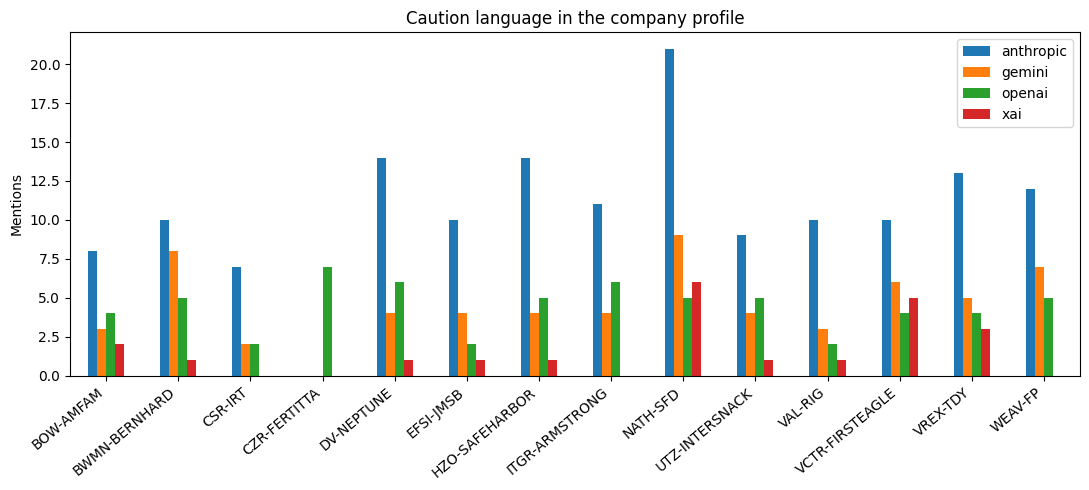

provider,anthropic,gemini,openai,xai
deal_id,,,,
BOW-AMFAM,8.0,3.0,4.0,2.0
BWMN-BERNHARD,10.0,8.0,5.0,1.0
CSR-IRT,7.0,2.0,2.0,0.0
CZR-FERTITTA,NaN,NaN,7.0,NaN
DV-NEPTUNE,14.0,4.0,6.0,1.0
EFSI-JMSB,10.0,4.0,2.0,1.0
HZO-SAFEHARBOR,14.0,4.0,5.0,1.0
ITGR-ARMSTRONG,11.0,4.0,6.0,0.0
NATH-SFD,21.0,9.0,5.0,6.0


In [23]:
CAUTION = {
    "missing": r"\bmissing\b",
    "not in the filings": r"not in the filing",
    "assume": r"\bassum",
    "could not verify": r"could not verify|not verified|unverified",
    "illustrative": r"illustrative",
}

caution_rows = []
for path in sorted(RUNS.rglob("*.json")):
    if any("checkpoint" in part for part in path.parts):
        continue
    payload = json.loads(path.read_text())
    profile = payload.get("profile") or ""
    if not profile:
        continue
    caution_rows.append({
        "deal_id": payload.get("deal_id") or path.parent.parent.name,
        "stamp": path.parent.name,
        "provider": payload.get("provider"),
        **{name: len(re.findall(pattern, profile, flags=re.IGNORECASE)) for name, pattern in CAUTION.items()},
    })
caution = pd.DataFrame(caution_rows)
caution = caution.sort_values("stamp").groupby(["deal_id", "provider"], as_index=False).tail(1)
caution["caution_mentions"] = caution[list(CAUTION)].sum(axis=1)
print(caution.drop(columns=["stamp"]).to_string(index=False))

deal_provider_bars(caution, "caution_mentions", "Caution language in the company profile", "Mentions")


## 15. Failed calls

These rows have no forecast. They are grouped by the kind of error so a bad model id is not mixed with a busy server.

kind       400 bad key  400 temperature  404 model not found  429 quota  503 busy  other
provider                                                                                
anthropic            0                1                    4          0         0      0
gemini               0                0                    0          1        29     20
xai                  2                0                    0          0         0      0


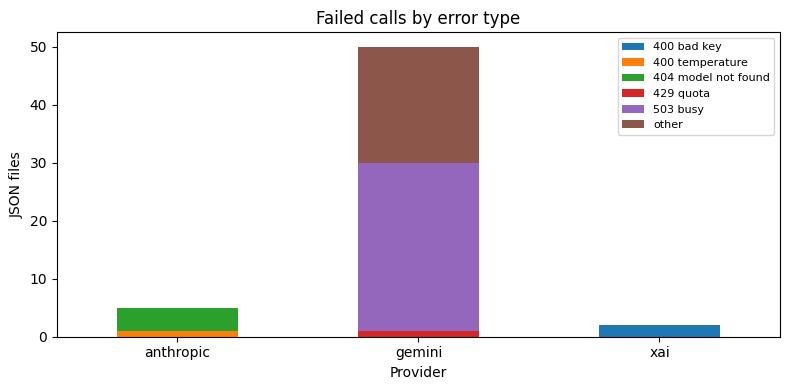

In [24]:
def error_kind(message):
    text = message or ""
    lowered = text.lower()
    if "no longer available" in lowered or "not_found" in lowered or "not found" in lowered:
        return "404 model not found"
    if "quota" in lowered or "429" in lowered:
        return "429 quota"
    if "high demand" in lowered or "503" in lowered or "unavailable" in lowered:
        return "503 busy"
    if "api key" in lowered:
        return "400 bad key"
    if "temperature" in lowered:
        return "400 temperature"
    if not text:
        return "no error text"
    return "other"


failures = runs.loc[~runs["ok"]].copy()
failures["kind"] = failures["error"].apply(error_kind)
counts = failures.groupby(["provider", "kind"]).size().unstack(fill_value=0)
print(counts.to_string())
fig, ax = plt.subplots(figsize=(8, 4))
counts.plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Failed calls by error type")
ax.set_xlabel("Provider")
ax.set_ylabel("JSON files")
ax.legend(title="", fontsize=8)
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
plt.show()


## 16. Which forecasts exist

One cell per deal and provider. A filled cell is a finished forecast. An empty cell is a deal in the register that this provider has not successfully scored. The disagreement charts below only compare the filled cells.


provider         anthropic  gemini  openai  xai
deal_id                                        
ITGR-ARMSTRONG           1       1       1    1
WEAV-FP                  1       1       1    1
NATH-SFD                 1       1       1    1
VREX-TDY                 1       1       1    1
DV-NEPTUNE               1       1       1    1
BWMN-BERNHARD            1       1       1    1
CSR-IRT                  1       1       1    1
HZO-SAFEHARBOR           1       1       1    1
BOW-AMFAM                1       1       1    1
UTZ-INTERSNACK           1       1       1    1
VCTR-FIRSTEAGLE          1       1       1    1
EFSI-JMSB                1       1       1    1
VAL-RIG                  1       1       1    1

53 latest provider runs have a forecast. The register has 13 deals.


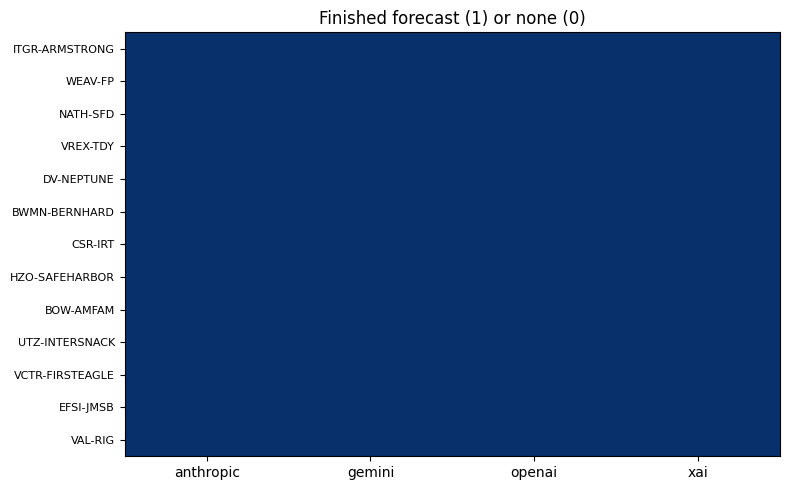

In [25]:
register = pd.read_csv(ROOT / "M&A Datasets.csv")
register.columns = [name.strip() for name in register.columns]
register_ids = [deal_id for deal_id in register["Deal id"].dropna().astype(str) if deal_id.strip()]
latest_runs = runs.sort_values("stamp").groupby(["deal_id", "provider"], as_index=False).tail(1)
coverage = latest_runs.pivot(index="deal_id", columns="provider", values="ok")
coverage = coverage.reindex(register_ids)
shown = coverage.map(lambda value: 1 if value is True else 0)
print(shown.to_string())
print()
finished = int(latest_runs["ok"].sum())
possible = coverage.size
print(f"{finished} latest provider runs have a forecast. The register has {len(register_ids)} deals.")

plot_coverage = coverage.map(lambda value: 1 if value is True else 0)
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(plot_coverage.to_numpy(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(plot_coverage.columns)))
ax.set_xticklabels(plot_coverage.columns)
ax.set_yticks(range(len(plot_coverage.index)))
ax.set_yticklabels(plot_coverage.index, fontsize=8)
ax.set_title("Finished forecast (1) or none (0)")
fig.tight_layout()
plt.show()


## 17. One success percent, or two questions

P(close) and P(creates value if closed) are separate. When a model writes both, the product is the chance the deal closes and creates value. The column next to it is the single success percent used in the disagreement chart. A blank means the model did not split the two questions.


        deal_id  provider  p_success  p_close  p_value  product  product_minus_success
   CZR-FERTITTA    openai       75.0      NaN      NaN      NaN                    NaN
 ITGR-ARMSTRONG    openai       80.0      NaN      NaN      NaN                    NaN
 ITGR-ARMSTRONG       xai        NaN     82.5      NaN      NaN                    NaN
 ITGR-ARMSTRONG anthropic       68.0     92.0      NaN      NaN                    NaN
 ITGR-ARMSTRONG    gemini        NaN      NaN      NaN      NaN                    NaN
        WEAV-FP       xai        NaN      NaN      NaN      NaN                    NaN
        WEAV-FP    gemini       78.0      NaN      NaN      NaN                    NaN
        WEAV-FP anthropic      100.0     62.0     62.0     38.4                  -61.6
        WEAV-FP    openai       80.0      NaN      NaN      NaN                    NaN
       NATH-SFD       xai        NaN      NaN      NaN      NaN                    NaN
       NATH-SFD    openai       80.0      N

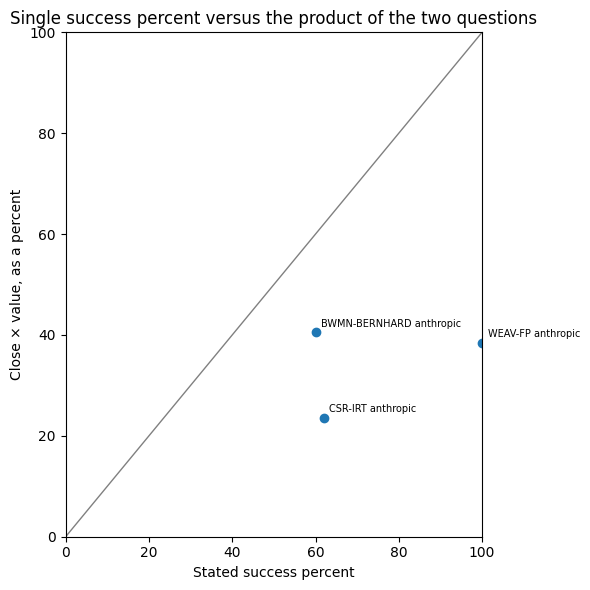

In [26]:
coherence = latest_scores[["deal_id", "provider", "p_success", "forecast"]].copy()
split = coherence["forecast"].apply(close_and_value)
coherence = pd.concat([coherence.reset_index(drop=True), split.reset_index(drop=True)], axis=1)
coherence["product"] = coherence["p_close"] * coherence["p_value"] / 100
coherence["product_minus_success"] = coherence["product"] - coherence["p_success"]
show = coherence.drop(columns=["forecast"]).round(1)
print(show.to_string(index=False))
both = coherence.dropna(subset=["product", "p_success"])
if both.empty:
    print("No forecast wrote both a close percent and a value percent.")
else:
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(both["p_success"], both["product"])
    for row in both.itertuples():
        ax.annotate(f"{row.deal_id} {row.provider}", (row.p_success, row.product), fontsize=7, xytext=(4, 4), textcoords="offset points")
    ax.plot([0, 100], [0, 100], color="gray", linewidth=1)
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 100)
    ax.set_xlabel("Stated success percent")
    ax.set_ylabel("Close × value, as a percent")
    ax.set_title("Single success percent versus the product of the two questions")
    fig.tight_layout()
    plt.show()


## 18. Does a rerun move the number

Same deal and same provider, first saved forecast versus the latest. A large gap means the disagreement between models is partly rerun noise.


        deal_id  provider      first_stamp       last_stamp  first_success  last_success  change  n_runs
      BOW-AMFAM anthropic 20261027T162504Z 20261106T155133Z           85.0          68.0   -17.0       2
      BOW-AMFAM    gemini 20261028T133121Z 20261109T152835Z           75.0          75.0     0.0       3
      BOW-AMFAM    openai 20261027T162504Z 20261109T152835Z           85.0          75.0   -10.0       3
      BOW-AMFAM       xai 20261106T155133Z 20261109T152835Z           78.0          75.0    -3.0       2
  BWMN-BERNHARD anthropic 20261027T154708Z 20261109T151959Z           90.0          60.0   -30.0       4
  BWMN-BERNHARD    gemini 20261028T132923Z 20261109T151959Z           85.0          80.0    -5.0       3
  BWMN-BERNHARD    openai 20261027T154708Z 20261109T151959Z           85.0          75.0   -10.0       3
        CSR-IRT anthropic 20261106T154845Z 20261109T152259Z           64.0          62.0    -2.0       2
        CSR-IRT    gemini 20261028T133026Z 20261109T152

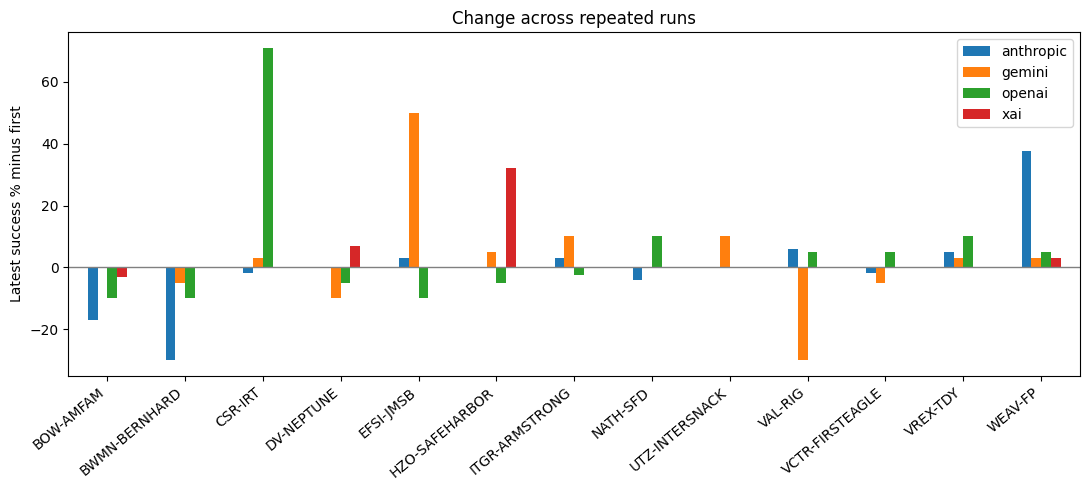

In [27]:
repeats = scored.dropna(subset=["p_success"]).sort_values("stamp")
counts = repeats.groupby(["deal_id", "provider"]).size()
repeat_keys = counts[counts >= 2].index
if len(repeat_keys) == 0:
    print("No deal has two finished forecasts from the same provider.")
else:
    rows = []
    for deal_id, provider in repeat_keys:
        group = repeats[(repeats["deal_id"] == deal_id) & (repeats["provider"] == provider)]
        first, last = group.iloc[0], group.iloc[-1]
        rows.append({
            "deal_id": deal_id,
            "provider": provider,
            "first_stamp": first["stamp"],
            "last_stamp": last["stamp"],
            "first_success": first["p_success"],
            "last_success": last["p_success"],
            "change": last["p_success"] - first["p_success"],
            "n_runs": len(group),
        })
    stability = pd.DataFrame(rows)
    print(stability.round(1).to_string(index=False))
    pivot = stability.pivot(index="deal_id", columns="provider", values="change")
    fig, ax = plt.subplots(figsize=(11, 5))
    pivot.plot(kind="bar", ax=ax)
    ax.axhline(0, color="gray", linewidth=1)
    ax.set_ylabel("Latest success % minus first")
    ax.set_xlabel("")
    ax.set_title("Change across repeated runs")
    ax.legend(title="")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
    fig.tight_layout()
    plt.show()


## 19. ROI minus WACC

This is the success-case return minus the cost of capital the same model wrote. A positive number is the model's own statement that the buyer earns more than its hurdle. A blank means one of the two figures was not stated.


        deal_id  provider  roi  wacc  roi_minus_wacc
   CZR-FERTITTA    openai 11.5   8.0             3.5
 ITGR-ARMSTRONG    openai 16.5  10.0             6.5
 ITGR-ARMSTRONG       xai  NaN   NaN             NaN
 ITGR-ARMSTRONG anthropic  7.0   9.0            -2.0
 ITGR-ARMSTRONG    gemini 20.0   6.0            14.0
        WEAV-FP       xai  NaN   NaN             NaN
        WEAV-FP    gemini  NaN  11.5             NaN
        WEAV-FP anthropic 13.0  11.5             1.5
        WEAV-FP    openai  9.0  11.0            -2.0
       NATH-SFD       xai  NaN   NaN             NaN
       NATH-SFD    openai 13.5   8.0             5.5
       NATH-SFD    gemini 12.0  12.0             0.0
       NATH-SFD anthropic  6.0   3.5             2.5
       VREX-TDY       xai  NaN   NaN             NaN
       VREX-TDY anthropic 15.0   8.5             6.5
       VREX-TDY    openai 27.5   8.8            18.8
       VREX-TDY    gemini 15.0   8.7             6.3
     DV-NEPTUNE anthropic 30.0   6.8          

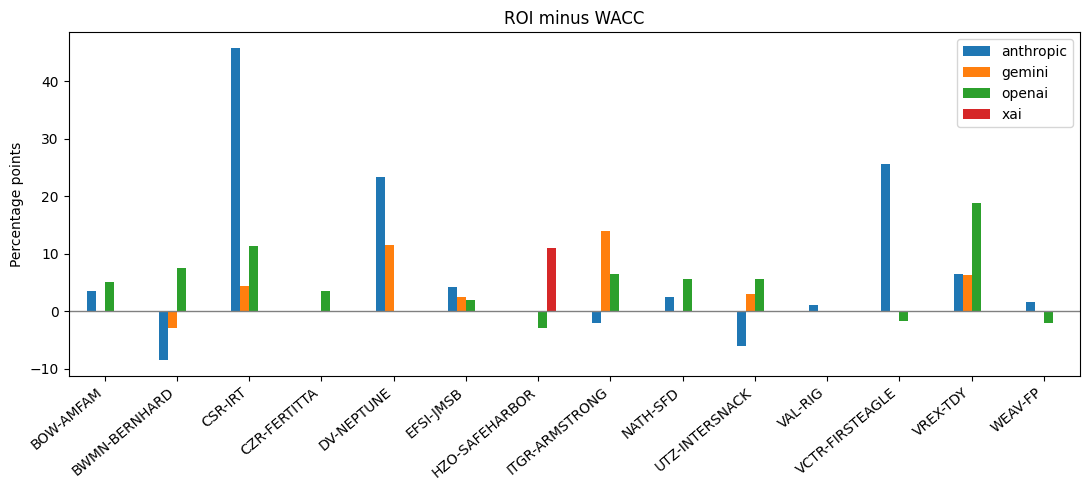

In [28]:
value_gap = financials[["deal_id", "provider", "roi", "wacc"]].copy()
value_gap["roi_minus_wacc"] = value_gap["roi"] - value_gap["wacc"]
print(value_gap.round(1).to_string(index=False))
pivot = value_gap.pivot(index="deal_id", columns="provider", values="roi_minus_wacc")
if pivot.notna().sum().sum() == 0:
    print("No model stated both ROI and WACC.")
else:
    fig, ax = plt.subplots(figsize=(11, 5))
    pivot.plot(kind="bar", ax=ax)
    ax.axhline(0, color="gray", linewidth=1)
    ax.set_ylabel("Percentage points")
    ax.set_xlabel("")
    ax.set_title("ROI minus WACC")
    ax.legend(title="")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
    fig.tight_layout()
    plt.show()


## 20. Cash or stock, sponsor or not

The tag comes from words in the situational analysis. "Sponsor" means the text says financial sponsor, private equity, or LBO. The bars are the mean stated success percent inside each group.


        deal_id  provider consideration               buyer  p_success
   CZR-FERTITTA    openai         mixed no sponsor language       75.0
 ITGR-ARMSTRONG    openai         mixed             sponsor       80.0
 ITGR-ARMSTRONG       xai         mixed no sponsor language        NaN
 ITGR-ARMSTRONG anthropic          cash             sponsor       68.0
 ITGR-ARMSTRONG    gemini         mixed no sponsor language        NaN
        WEAV-FP       xai         mixed no sponsor language        NaN
        WEAV-FP    gemini          cash no sponsor language       78.0
        WEAV-FP anthropic          cash no sponsor language      100.0
        WEAV-FP    openai         mixed             sponsor       80.0
       NATH-SFD       xai         mixed             sponsor        NaN
       NATH-SFD    openai         mixed             sponsor       80.0
       NATH-SFD    gemini         mixed no sponsor language       75.0
       NATH-SFD anthropic         mixed             sponsor        NaN
      

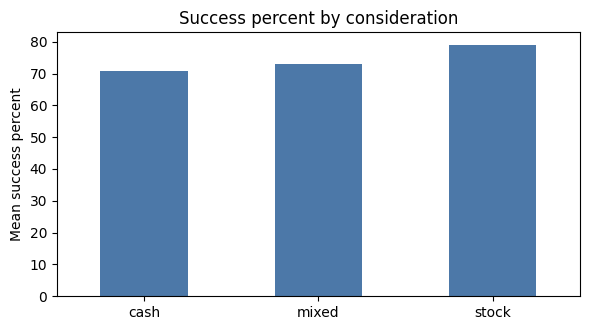

                     count  mean
buyer                           
no sponsor language     30  71.1
sponsor                 23  74.9



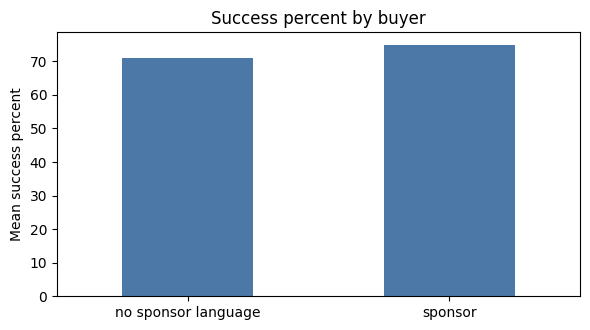

In [29]:
def structure_tags(text):
    """Read consideration and buyer type from the situational analysis."""
    cash = bool(re.search(r"\bcash\b", text, flags=re.IGNORECASE))
    stock = bool(re.search(r"\bstock\b", text, flags=re.IGNORECASE))
    if cash and stock:
        consideration = "mixed"
    elif cash:
        consideration = "cash"
    elif stock:
        consideration = "stock"
    else:
        consideration = "not stated"
    sponsor = bool(re.search(r"financial sponsor|private equity|\bLBO\b", text, flags=re.IGNORECASE))
    return pd.Series({
        "consideration": consideration,
        "buyer": "sponsor" if sponsor else "no sponsor language",
    })


tagged = situations[["deal_id", "provider", "situational"]].copy()
tagged = pd.concat(
    [tagged.reset_index(drop=True), tagged["situational"].apply(structure_tags).reset_index(drop=True)],
    axis=1,
)
tagged = tagged.merge(
    latest_scores[["deal_id", "provider", "p_success"]],
    on=["deal_id", "provider"],
    how="left",
)
print(tagged.drop(columns=["situational"]).to_string(index=False))
print()
for column in ("consideration", "buyer"):
    summary = tagged.groupby(column).agg(count=("deal_id", "size"), mean=("p_success", "mean")).round(1)
    print(summary.to_string())
    print()
    fig, ax = plt.subplots(figsize=(6, 3.4))
    summary["mean"].plot(kind="bar", ax=ax, color="#4c78a8")
    ax.set_ylabel("Mean success percent")
    ax.set_xlabel("")
    ax.set_title(f"Success percent by {column}")
    ax.tick_params(axis="x", rotation=0)
    fig.tight_layout()
    plt.show()


## 21. Deal terms the models do not share

A row is a deal where two models printed different numbers for the same term, or where a model said the filing packet describes more than one transaction. Those forecasts are a weak comparison until the packet is one deal.


In [30]:
term_problems = []
for deal_id, group in number_rows.groupby("deal_id"):
    for column in ("offer_per_share", "premium_pct", "termination_fee_m", "outside_date"):
        values = group[column].dropna()
        if values.astype(str).nunique() > 1:
            term_problems.append({
                "deal_id": deal_id,
                "issue": column,
                "detail": ", ".join(f"{row.provider} {getattr(row, column)}" for row in group.itertuples() if pd.notna(getattr(row, column))),
            })

two_deals = situations[["deal_id", "provider", "situational"]].copy()
two_deals["two_transactions"] = two_deals["situational"].str.contains(
    r"unrelated|two transactions|not one deal|two separate",
    case=False,
    na=False,
)
for row in two_deals[two_deals["two_transactions"]].itertuples():
    term_problems.append({
        "deal_id": row.deal_id,
        "issue": "more than one transaction",
        "detail": row.provider,
    })

if not term_problems:
    print("No conflicting terms, and no model said the packet covers two transactions.")
else:
    print(pd.DataFrame(term_problems).to_string(index=False))


 deal_id           issue                                           detail
 CSR-IRT offer_per_share                      openai 0.77, anthropic 0.09
NATH-SFD offer_per_share xai 7.4, openai 102.0, gemini 7.4, anthropic 7.4


## 22. Missing facts versus how tight the percent is

The missing count is from the company profile. The width is the success range in the forecast: 80–85 has width 5, and a single number such as 75 has width 0. A high missing count with a width of 0 means the model listed gaps and still gave a point estimate.


        deal_id  provider  success_width  caution_mentions
   CZR-FERTITTA    openai            0.0                 7
 ITGR-ARMSTRONG    openai            0.0                 6
 ITGR-ARMSTRONG       xai            NaN                 0
 ITGR-ARMSTRONG anthropic            NaN                11
 ITGR-ARMSTRONG    gemini            NaN                 4
        WEAV-FP       xai            NaN                 0
        WEAV-FP    gemini            0.0                 7
        WEAV-FP anthropic            0.0                12
        WEAV-FP    openai            0.0                 5
       NATH-SFD       xai            NaN                 6
       NATH-SFD    openai            NaN                 5
       NATH-SFD    gemini            0.0                 9
       NATH-SFD anthropic            NaN                21
       VREX-TDY       xai            0.0                 3
       VREX-TDY anthropic            0.0                13
       VREX-TDY    openai            NaN                

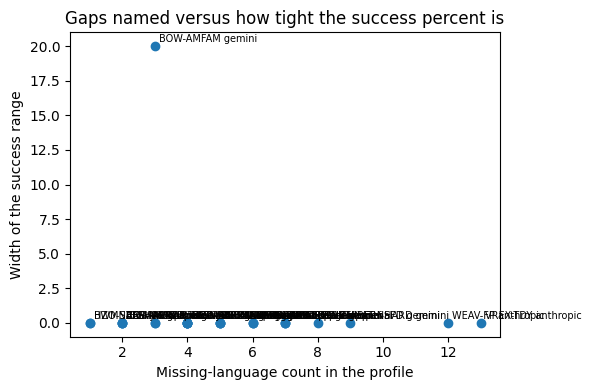

In [31]:
def success_width(text):
    """Width of the first success range. Zero when the model gave one number."""
    match = re.search(
        r"(?:probability of success|success probability|overall).{0,80}?(\d{1,3}(?:\.\d+)?)\s*[–\-−]\s*(\d{1,3}(?:\.\d+)?)\s*%",
        text or "",
        flags=re.IGNORECASE | re.DOTALL,
    )
    if match:
        return abs(float(match.group(2)) - float(match.group(1)))
    if first_percent(text or "", ["probability of success", "success probability", "overall"]):
        return 0.0
    return None


width_rows = latest_scores[["deal_id", "provider", "forecast"]].copy()
width_rows["success_width"] = width_rows["forecast"].apply(success_width)
gap_table = width_rows.merge(
    caution[["deal_id", "provider", "caution_mentions"]],
    on=["deal_id", "provider"],
    how="left",
)
print(gap_table.drop(columns=["forecast"]).round(1).to_string(index=False))
usable = gap_table.dropna(subset=["success_width", "caution_mentions"])
if not usable.empty:
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(usable["caution_mentions"], usable["success_width"])
    for row in usable.itertuples():
        ax.annotate(f"{row.deal_id} {row.provider}", (row.caution_mentions, row.success_width), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("Missing-language count in the profile")
    ax.set_ylabel("Width of the success range")
    ax.set_title("Gaps named versus how tight the success percent is")
    fig.tight_layout()
    plt.show()


## 23. Language that describes an outcome already decided

These phrases belong in a filing after a vote, a close, or a termination. A hit in a profile or forecast means that run is describing a result rather than a prospect. The scanner is a flag, not proof of outside knowledge.


In [32]:
LEAK_PATTERNS = {
    "vote result": r"\b(votes?\s+(for|against|cast|represented)|stockholders?\s+voted)\b",
    "closing": r"\b(merger\s+(was\s+)?(completed|consummated)|transaction\s+closed|closing\s+occurred)\b",
    "termination": r"\b(terminated\s+the\s+merger\s+agreement|agreement\s+was\s+terminated|deal\s+was\s+abandoned)\b",
    "schedule slip": r"\b(outside\s+date\s+(was\s+)?extended|closing\s+(was\s+)?delayed)\b",
    "price after announcement": r"\b(shares?\s+(closed|traded)\s+at|after\s+the\s+announcement,?\s+the\s+stock)\b",
}


def leak_hits(text):
    counts = {}
    for name, pattern in LEAK_PATTERNS.items():
        counts[name] = len(re.findall(pattern, text or "", flags=re.IGNORECASE))
    return counts


leak_rows = []
for path in sorted(RUNS.rglob("*.json")):
    if any("checkpoint" in part for part in path.parts):
        continue
    payload = json.loads(path.read_text())
    profile = payload.get("profile") or ""
    forecast = payload.get("forecast") or ""
    if not profile and not forecast:
        continue
    counts = leak_hits(profile + "\n" + forecast)
    leak_rows.append({
        "deal_id": payload.get("deal_id") or path.parent.parent.name,
        "stamp": path.parent.name,
        "provider": payload.get("provider"),
        **counts,
    })
leaks = pd.DataFrame(leak_rows)
leaks = leaks.sort_values("stamp").groupby(["deal_id", "provider"], as_index=False).tail(1)
leaks["hits"] = leaks[list(LEAK_PATTERNS)].sum(axis=1)
print(leaks.drop(columns=["stamp"]).to_string(index=False))
flagged = leaks[leaks["hits"] > 0]
if flagged.empty:
    print("No saved profile or forecast matched the outcome phrases.")


        deal_id  provider  vote result  closing  termination  schedule slip  price after announcement  hits
   CZR-FERTITTA    openai            0        0            0              0                         0     0
 ITGR-ARMSTRONG    openai            0        0            0              0                         0     0
 ITGR-ARMSTRONG       xai            0        0            0              0                         0     0
 ITGR-ARMSTRONG anthropic            1        0            0              0                         0     1
 ITGR-ARMSTRONG    gemini            1        0            0              0                         0     1
        WEAV-FP       xai            0        0            0              0                         0     0
        WEAV-FP    gemini            0        0            0              0                         0     0
        WEAV-FP anthropic            2        0            0              0                         0     2
        WEAV-FP    openai   